# Question 1：Vector Add

工作区根目录的 `vecAdd.cu` 在原始示例基础上修改，保留 `add`、`dim3 grid/tpb` 和原来的内存操作顺序。每个 block 仍使用 **32 个线程**。

先在 Colab 打开本 notebook，再手动把工作区根目录的 **`vecAdd.cu`** 上传到 Colab 的 **`/content`**。按下面顺序运行即可。


### 1. 检查 GPU 和 CUDA


In [8]:
!nvidia-smi
!nvcc --version

Fri Nov  6 02:57:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 2. 确认上传的源码


In [9]:
%cd /content
!ls -l vecAdd.cu


/content
-rw-r--r-- 1 root root 2937 Nov  6 02:57 vecAdd.cu


### 3. 编译

沿用教程中的 `sm_75`（Tesla T4）。修改源码后，重新上传并编译。


In [10]:
!nvcc -arch=sm_75 vecAdd.cu -o vecAdd


### 4. 测试 N = 512

程序只接收一个参数：向量长度 N。每次运行一次 kernel。

输出包含线程/block 配置、三个阶段的时间和最大误差 `max_error`。误差为 0 表示 CPU/GPU 数值完全相等。


In [11]:
!./vecAdd 512


N,threads,blocks,H2D_ms,kernel_ms,D2H_ms,max_error
512,32,16,0.033140,0.110865,0.015974,0


### 5. 测试 N = 263149

`grid` 向上取整，kernel 中的 `if (i < N)` 防止越界。


In [12]:
!./vecAdd 263149


N,threads,blocks,H2D_ms,kernel_ms,D2H_ms,max_error
263149,32,8224,0.710011,0.128984,0.792980,0


### 6. 导入绘图库


In [13]:
import io
import subprocess
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


### 7. 测量不同长度

每个长度只测量一次。C++ 源码中的 CPU 计时覆盖 H2D、kernel、D2H；每个阶段结束时等待 GPU 完成。kernel 时间包含启动和同步开销。

结果保存在 Colab 的 `timing_results.csv`，不自动下载。


In [14]:
lengths = [
    512, 1024, 4096, 16384, 65536, 131072, 263149, 524288,
    1048576, 2097152, 4194304, 6291456,
    8388608, 10485760, 12582912, 16777216,
]
results = []
for N in lengths:
    output = subprocess.check_output(['./vecAdd', str(N)], text=True)
    results.append(pd.read_csv(io.StringIO(output)))

timing = pd.concat(results, ignore_index=True)
timing.to_csv('timing_results.csv', index=False)
display(timing)


,N,threads,blocks,H2D_ms,kernel_ms,D2H_ms,max_error
0,512,32,16,0.069857,0.128984,0.019073,0
1,1024,32,32,0.031948,0.100136,0.014067,0
2,4096,32,128,0.041962,0.092983,0.025034,0
3,16384,32,512,0.085115,0.146866,0.064135,0
4,65536,32,2048,0.236988,0.100136,0.201941,0
5,131072,32,4096,0.349045,0.104904,0.444889,0
6,263149,32,8224,0.639915,0.109911,0.809193,0
7,524288,32,16384,1.240969,0.181198,1.784801,0
8,1048576,32,32768,2.285004,0.151873,2.790928,0
9,2097152,32,65536,3.913879,0.206947,5.444050,0


### 8. 堆叠柱状图

H2D 包含两个输入向量，D2H 包含一个输出向量。


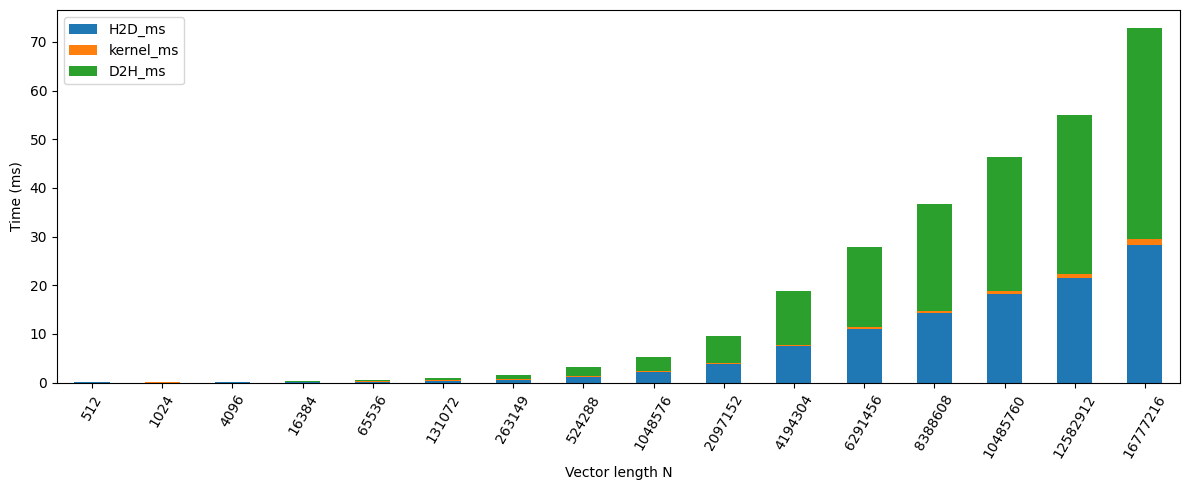

In [15]:
timing.set_index('N')[['H2D_ms', 'kernel_ms', 'D2H_ms']].plot(
    kind='bar', stacked=True, figsize=(12, 5)
)
plt.xlabel('Vector length N')
plt.ylabel('Time (ms)')
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig('timing_breakdown.png')
plt.show()


### 9. 查看 CPU/GPU 误差


In [16]:
display(timing[['N', 'max_error']])


,N,max_error
0,512,0
1,1024,0
2,4096,0
3,16384,0
4,65536,0
5,131072,0
6,263149,0
7,524288,0
8,1048576,0
9,2097152,0


### 10. 查看 Nsight Compute 的分析模块

与教程一样使用 `ncu`。如果提示找不到命令，需要先在 Colab 配置 Nsight Compute。


In [17]:
!ncu --list-sections


-------------------------------------------- ----------------------------------------------------------------- ------- --------------------------------------------------
Identifier                                   Display Name                                                      Enabled Filename                                          
-------------------------------------------- ----------------------------------------------------------------- ------- --------------------------------------------------
C2CLink                                      C2CLink                                                           no      ...sight Compute/2025.3.1/Sections/C2CLink.section
ComputeWorkloadAnalysis                      Compute Workload Analysis                                         no      ...25.3.1/Sections/ComputeWorkloadAnalysis.section
InstructionStats                             Instruction Statistics                                            no      ...2025.3.1/Sections/Instructio

### 11. N = 512 的 Achieved Occupancy

读取输出中 Occupancy 表格的 **Achieved Occupancy**。


In [18]:
!ncu --section Occupancy ./vecAdd 512


==PROF== Connected to process 49000 (/content/vecAdd)
==PROF== Profiling "add" - 0: 0%....50%....100% - 1 pass
N,threads,blocks,H2D_ms,kernel_ms,D2H_ms,max_error
512,32,16,0.046015,869.490147,0.053883,0
==PROF== Disconnected from process 49000
[49000] vecAdd@127.0.0.1
  add(float *, float *, float *, int) (16, 1, 1)x(32, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: Occupancy
    ------------------------------- ----------- ------------
    Metric Name                     Metric Unit Metric Value
    ------------------------------- ----------- ------------
    Block Limit SM                        block           16
    Block Limit Registers                 block          128
    Block Limit Shared Mem                block           16
    Block Limit Warps                     block           32
    Theoretical Active Warps per SM        warp           16
    Theoretical Occupancy                     %           50
    Achieved Occupancy                        %         3.12

### 12. N = 263149 的 Achieved Occupancy

如果出现 `ERR_NVGPUCTRPERM`，当前 Colab 不允许访问性能计数器，无法在该运行时测得占用率。前面的计时和绘图单独运行，不使用 Nsight 插桩后的时间。


In [19]:
!ncu --section Occupancy ./vecAdd 263149


==PROF== Connected to process 49039 (/content/vecAdd)
==PROF== Profiling "add" - 0: 0%....50%....100% - 1 pass
N,threads,blocks,H2D_ms,kernel_ms,D2H_ms,max_error
263149,32,8224,0.669003,877.277851,0.955105,0
==PROF== Disconnected from process 49039
[49039] vecAdd@127.0.0.1
  add(float *, float *, float *, int) (8224, 1, 1)x(32, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: Occupancy
    ------------------------------- ----------- ------------
    Metric Name                     Metric Unit Metric Value
    ------------------------------- ----------- ------------
    Block Limit SM                        block           16
    Block Limit Registers                 block          128
    Block Limit Shared Mem                block           16
    Block Limit Warps                     block           32
    Theoretical Active Warps per SM        warp           16
    Theoretical Occupancy                     %           50
    Achieved Occupancy                        %      